In [29]:
import os

if os.path.exists("/content/student-mat.csv"):
    print("student-mat.csv is available.")
else:
    print("ERROR: student-mat.csv is missing.")

student-mat.csv is available.


In [30]:
import pandas as pd

df = pd.read_csv("/content/student-mat.csv", sep=";")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 395
Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# DS-A1: Data Provenance and Measurement Audit

## Student Performance Dataset

**Research Question:**  
Is students' study time associated with their final mathematics grade?

## 1. Data Source and Provenance

**Dataset:** Student Performance  
**Source:** UCI Machine Learning Repository  
**Creator:** Paulo Cortez  
**Data:** Mathematics course student performance (`student-mat.csv`)  
**Sample size:** 395 students  
**Number of variables:** 33  
**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

The dataset contains student achievement and related demographic, social, and school information from secondary school students. For this audit, only the Mathematics course dataset (`student-mat.csv`) is used.

In [31]:
import hashlib

with open("/content/student-mat.csv", "rb") as f:
    sha256 = hashlib.sha256(f.read()).hexdigest()

print("SHA-256:", sha256)

SHA-256: e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80


## 2. Study Definition

**Stakeholder:** Secondary-school teachers and education researchers.

**Population:** Secondary-school students similar to those represented in the original study.

**Sample:** 395 students in the Mathematics course dataset.

**Unit of analysis:** One student.

**Target:** Final mathematics grade (`G3`), measured from 0 to 20.

**Exposure / variable of interest:** Weekly study time (`studytime`), recorded as an ordinal category.

**Estimand:** The difference in average final mathematics grade (`G3`) across the recorded study-time categories.

**Scope:** This analysis examines association, not causation. It does not claim that increasing study time causes a higher mathematics grade.

## 3. Data-Generating Process and Provenance

The data-generating process is summarized as:

**Secondary-school students**  
↓  
**Student demographic, social, school, and academic information collected**  
↓  
**Mathematics course records created**  
↓  
**Student Performance dataset prepared by the original researchers**  
↓  
**Dataset published in the UCI Machine Learning Repository**  
↓  
**`student-mat.csv` downloaded for this analysis**  
↓  
**Data quality and measurement audit performed in this notebook**

This lineage shows how the observations move from the original students and school records to the dataset used in this analysis.

## 4. Data Quality Audit

The following checks evaluate the structure and basic quality of the dataset.

In [32]:
print("Dataset shape:", df.shape)

print("\n--- Data types ---")
print(df.dtypes)

print("\n--- Missing values ---")
print("Total missing values:", df.isnull().sum().sum())

print("\n--- Duplicate rows ---")
print("Duplicate rows:", df.duplicated().sum())

print("\n--- Key variable ranges ---")
print("studytime values:", sorted(df["studytime"].unique()))
print("G3 minimum:", df["G3"].min())
print("G3 maximum:", df["G3"].max())

Dataset shape: (395, 33)

--- Data types ---
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

--- Missing values ---
Total missing values: 0

--- Duplicate rows ---
Duplicate rows: 0

--- Key variable ranges ---
studytime values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
G3 minimum: 0
G3 maximum: 20


### Audit Results

The dataset contains 395 observations and 33 variables. No missing values or duplicate rows were detected.

The key variables are within their documented ranges:
- `studytime`: 1–4
- `G3`: 0–20

Therefore, no obvious missingness, duplication, or range violations were identified in the key variables.

In [33]:
print("--- Grade distributions ---")
print(df[["G1", "G2", "G3"]].describe())

print("\n--- Correlation with final grade G3 ---")
print(df[["G1", "G2", "G3"]].corr()["G3"].sort_values(ascending=False))

--- Grade distributions ---
               G1          G2          G3
count  395.000000  395.000000  395.000000
mean    10.908861   10.713924   10.415190
std      3.319195    3.761505    4.581443
min      3.000000    0.000000    0.000000
25%      8.000000    9.000000    8.000000
50%     11.000000   11.000000   11.000000
75%     13.000000   13.000000   14.000000
max     19.000000   19.000000   20.000000

--- Correlation with final grade G3 ---
G3    1.000000
G2    0.904868
G1    0.801468
Name: G3, dtype: float64


### Anomaly and Leakage Check

The grade variables are within their expected ranges. No obvious range anomalies were identified.

`G1` and `G2` are strongly correlated with the final grade `G3`:
- G1–G3 correlation: 0.801
- G2–G3 correlation: 0.905

These variables represent earlier course grades. If the objective were to predict `G3` before these grades became available, including `G1` or `G2` would create a potential temporal leakage risk. Therefore, their availability at prediction time must be considered before using them as predictors.

For the current research question, the main variable of interest is `studytime`, so `G1` and `G2` are not used to define the primary association.

## 5. Measurement and Construct Validity

### Study Time
The variable `studytime` represents weekly study time using four ordinal categories:

- 1 = less than 2 hours
- 2 = 2 to 5 hours
- 3 = 5 to 10 hours
- 4 = more than 10 hours

This variable is a proxy for actual study effort. Because it records broad categories rather than exact hours, students within the same category may have different study times. It may also be affected by self-reporting error.

### Final Mathematics Grade
The variable `G3` represents the final mathematics grade on a scale from 0 to 20.

`G3` is a direct academic outcome in the dataset, but it measures course performance rather than overall academic ability.

### Construct Validity
The research question concerns the association between study time and mathematics performance. `studytime` provides an approximate measure of study effort, while `G3` provides a direct measure of final mathematics performance. Therefore, the variables are suitable for the research question, but the limitations of the categorical study-time measure should be considered.

## 6. Study Time and Final Mathematics Grade

To examine the research question, the mean final mathematics grade (`G3`) is compared across the four study-time categories.

In [34]:
study_summary = df.groupby("studytime")["G3"].agg(["count", "mean", "median", "std"])
study_summary.round(2)

,count,mean,median,std
studytime,,,,
1,105,10.05,10.0,4.96
2,198,10.17,11.0,4.22
3,65,11.40,12.0,4.64
4,27,11.26,12.0,5.28


### Descriptive Result

The mean final mathematics grade differs across the study-time categories:

- Category 1 (<2 hours): mean G3 = 10.05 (n = 105)
- Category 2 (2–5 hours): mean G3 = 10.17 (n = 198)
- Category 3 (5–10 hours): mean G3 = 11.40 (n = 65)
- Category 4 (>10 hours): mean G3 = 11.26 (n = 27)

Students in the higher study-time categories generally have slightly higher average final mathematics grades. However, the pattern is not strictly increasing, since category 4 has a slightly lower mean than category 3.

These descriptive results suggest a possible positive association between study time and final mathematics grade, but they do not establish causation.

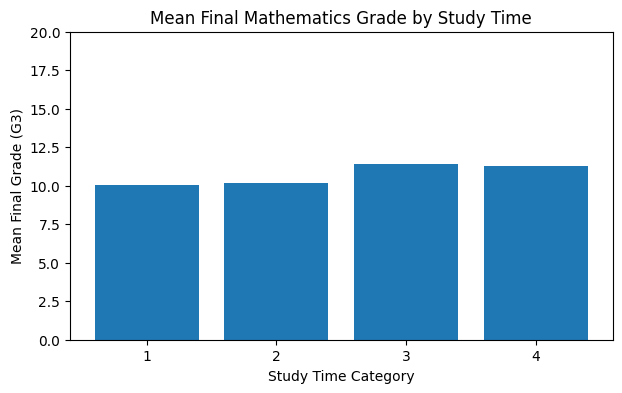

In [35]:
import matplotlib.pyplot as plt

means = df.groupby("studytime")["G3"].mean()

plt.figure(figsize=(7, 4))
plt.bar(means.index.astype(str), means.values)

plt.xlabel("Study Time Category")
plt.ylabel("Mean Final Grade (G3)")
plt.title("Mean Final Mathematics Grade by Study Time")
plt.ylim(0, 20)

plt.show()

In [36]:
import numpy as np

summary = df.groupby("studytime")["G3"].agg(["count", "mean", "std"])

summary["SE"] = summary["std"] / np.sqrt(summary["count"])
summary["CI_lower"] = summary["mean"] - 1.96 * summary["SE"]
summary["CI_upper"] = summary["mean"] + 1.96 * summary["SE"]

summary.round(2)

,count,mean,std,SE,CI_lower,CI_upper
studytime,,,,,,
1,105,10.05,4.96,0.48,9.10,11.00
2,198,10.17,4.22,0.30,9.58,10.76
3,65,11.40,4.64,0.58,10.27,12.53
4,27,11.26,5.28,1.02,9.27,13.25


### Uncertainty

Approximate 95% confidence intervals were calculated for the mean final mathematics grade in each study-time category.

- Category 1 (<2 hours): mean G3 = 10.05, 95% CI [9.10, 11.00]
- Category 2 (2–5 hours): mean G3 = 10.17, 95% CI [9.58, 10.76]
- Category 3 (5–10 hours): mean G3 = 11.40, 95% CI [10.27, 12.53]
- Category 4 (>10 hours): mean G3 = 11.26, 95% CI [9.27, 13.25]

The confidence interval is widest for category 4 because it has the smallest sample size (n = 27), indicating greater uncertainty in its estimated mean. The intervals overlap substantially across the four categories, so the descriptive differences in mean grades should be interpreted cautiously.

In [37]:
# Sensitivity analysis:
# Compare the result after combining study-time categories
# 1–2 = lower study time, 3–4 = higher study time

df["studytime_group"] = df["studytime"].apply(
    lambda x: "Lower study time (1-2)" if x <= 2 else "Higher study time (3-4)"
)

sensitivity = df.groupby("studytime_group")["G3"].agg(
    ["count", "mean", "median", "std"]
)

sensitivity.round(2)

,count,mean,median,std
studytime_group,,,,
Higher study time (3-4),92,11.36,12.0,4.81
Lower study time (1-2),303,10.13,10.0,4.48


### Sensitivity Analysis

As a sensitivity check, the four study-time categories were combined into two broader groups:

- Lower study time: categories 1–2
- Higher study time: categories 3–4

The higher study-time group had a mean final mathematics grade of 11.36 (n = 92), compared with 10.13 (n = 303) for the lower study-time group, a difference of approximately 1.23 points.

The direction of the result is consistent with the original four-category analysis: students reporting more study time had somewhat higher final mathematics grades on average. This suggests that the descriptive association is not dependent only on the original four-category grouping. However, this sensitivity analysis remains observational and does not establish a causal effect of study time on grades.

## 7. Limitations

Several limitations should be considered when interpreting the results of this analysis.

1. **Observational data:** The dataset is observational rather than experimental. Therefore, the observed association between study time and final mathematics grade cannot be interpreted as a causal relationship.

2. **Study-time measurement:** `studytime` is recorded using four broad ordinal categories rather than exact hours. Students within the same category may therefore have substantially different actual study times.

3. **Self-reported information:** Study time is based on reported behavior and may be affected by recall or reporting error.

4. **Potential confounding:** Other factors, such as prior academic performance, attendance, family background, and school-related characteristics, may be associated with both study time and final grades.

5. **Unequal group sizes:** The study-time categories contain different numbers of students. In particular, category 4 has only 27 students, resulting in greater uncertainty in its estimated mean.

6. **Generalizability:** The sample represents students from the schools included in the original dataset. The results should not automatically be generalized to all secondary-school students.

Overall, the analysis provides evidence of a descriptive association between reported study time and final mathematics grade, but the limitations of the measurements and observational study design should be considered when interpreting the results.

## 8. Conclusion

This audit examined the provenance, measurement quality, and suitability of the Student Performance dataset for investigating the association between reported study time and final mathematics grade.

The Mathematics dataset contains 395 students and 33 variables. No missing values, duplicate rows, or obvious range violations were identified in the key variables. The main exposure, `studytime`, is an ordinal measure of weekly study time, while `G3` represents the final mathematics grade on a scale from 0 to 20.

The descriptive analysis showed a modest positive association between reported study time and final mathematics grade. Students in study-time categories 1–4 had mean final grades of 10.05, 10.17, 11.40, and 11.26, respectively. A sensitivity analysis combining the categories into lower and higher study-time groups produced a similar pattern: the higher study-time group had a mean G3 of 11.36 compared with 10.13 in the lower study-time group.

However, the confidence intervals overlap, study time is measured using broad self-reported categories, and the dataset is observational. Therefore, these results should not be interpreted as evidence that increasing study time causes higher mathematics grades.

Overall, the dataset is suitable for examining a descriptive association between study time and final mathematics performance, provided that its measurement limitations, potential confounding, and observational design are clearly acknowledged.

## 9. Data Card

### Dataset
**Name:** Student Performance Dataset  
**Source:** UCI Machine Learning Repository  
**Creator:** Paulo Cortez  
**File used:** `student-mat.csv`  
**Sample size:** 395 students  
**Number of variables:** 33  
**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### Intended Use
This dataset is used in this audit to examine the association between reported weekly study time (`studytime`) and final mathematics grade (`G3`).

### Unit of Analysis
One student.

### Key Variables
- **studytime:** Weekly study time recorded as four ordinal categories.
- **G3:** Final mathematics grade, measured from 0 to 20.

### Data Quality
The audit identified no missing values or duplicate rows. The key variables were within their documented ranges.

### Important Limitations
The dataset is observational. Study time is self-reported and recorded using broad categories rather than exact hours. Potential confounding variables may affect both study time and academic performance. Therefore, the dataset can support analysis of association but cannot establish that increasing study time causes higher final grades.

### Dataset Integrity
A SHA-256 hash was calculated for the exact `student-mat.csv` file used in this analysis:

`e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80`

## 10. Data Dictionary

The dataset contains 33 variables. The key variables used in this audit are documented below.

| Variable | Type | Description | Values / Range | Role in this analysis |
|---|---|---|---|---|
| `studytime` | Ordinal integer | Weekly study time | 1 = <2 hours; 2 = 2–5 hours; 3 = 5–10 hours; 4 = >10 hours | Exposure / variable of interest |
| `G3` | Integer | Final mathematics grade | 0–20 | Target / outcome |
| `G1` | Integer | First-period mathematics grade | 0–20 | Prior academic performance; checked for potential leakage |
| `G2` | Integer | Second-period mathematics grade | 0–20 | Prior academic performance; checked for potential leakage |
| `absences` | Integer | Number of school absences | Recorded count | Potential contextual/confounding variable |
| `failures` | Integer | Number of past class failures | Recorded category/count | Potential contextual/confounding variable |

### Variable Interpretation

`studytime` is an ordinal rather than continuous measure. The difference between categories should therefore not be interpreted as an exact equal-hour increase.

`G3` is the final mathematics course grade and is used as the outcome for the research question.

`G1` and `G2` are earlier course grades. Because they occur close in time to the final grade and are strongly associated with `G3`, their availability at prediction time would need to be considered carefully to avoid temporal leakage in a predictive analysis.

The remaining variables provide demographic, family, school, social, and academic context. They are not treated as primary exposure variables in this audit.

## 11. AI-Use and Independent-Verification Log

### AI Use

AI assistance (ChatGPT) was used during the preparation of this notebook to help:

- organize the notebook structure;
- explain Python and pandas code;
- suggest data-quality and leakage checks;
- improve the clarity of written interpretations;
- identify limitations and possible measurement issues.

AI was not used as a source of empirical results. All numerical results reported in this notebook were produced by executing the code on the downloaded `student-mat.csv` dataset.

### Accepted and Rejected Advice

**Accepted advice:**  
Suggestions related to checking missing values, duplicate rows, variable ranges, potential leakage, descriptive summaries, uncertainty, and sensitivity analysis were implemented when they were relevant to the assignment.

**Rejected or limited advice:**  
Any interpretation implying that study time causes higher mathematics grades was not accepted because the dataset is observational. The analysis was therefore restricted to describing an association.

### Independent Verification

AI-assisted suggestions and analysis steps were independently verified by:

1. confirming the dataset dimensions and variable names directly from the loaded CSV file;
2. comparing `studytime` and `G3` ranges with the dataset documentation;
3. checking missing values and duplicate rows programmatically;
4. calculating a SHA-256 hash for the exact dataset file used;
5. rerunning the notebook code and checking that the reported numerical results match the generated outputs.

### Verification Boundary

AI-generated suggestions were treated as guidance rather than evidence. Dataset documentation and executed Python outputs were used as the primary evidence for the final conclusions.